# Template-Based Patient-Facing Explanations of SHAP



In [ ]:
!pip install -q shap xgboost textstat
import os, re, json, platform, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

import sklearn, scipy, xgboost, shap, textstat
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEED = 42
QUICK = False            # True = small grids / fewer repeats, for a quick check only
N_BOOT = 200 if QUICK else 2000
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "shap": shap.__version__, "textstat": textstat.__version__, "seed": SEED}
print(versions)

{'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'textstat': (0, 7, 13), 'seed': 42}


## 2. Data

In [ ]:
url = "/content/drive/MyDrive/pima-indians-diabetes.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI",
        "DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)
print(df.shape)
print(df["Outcome"].value_counts().rename({0:"non-diabetic",1:"diabetic"}))

zero_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
missing_report = {c: int((df[c] == 0).sum()) for c in zero_cols}
print("Physiologically impossible zeros (treated as missing):", missing_report)

# zeros -> NaN. Imputation is NOT done here; it is fitted on training data only (see pipelines).
X_all = df.drop(columns="Outcome").copy()
X_all[zero_cols] = X_all[zero_cols].replace(0, np.nan)
y_all = df["Outcome"].copy()
FEATURES = list(X_all.columns)

(768, 9)
Outcome
non-diabetic    500
diabetic        268
Name: count, dtype: int64
Physiologically impossible zeros (treated as missing): {'Glucose': 5, 'BloodPressure': 35, 'SkinThickness': 227, 'Insulin': 374, 'BMI': 11}


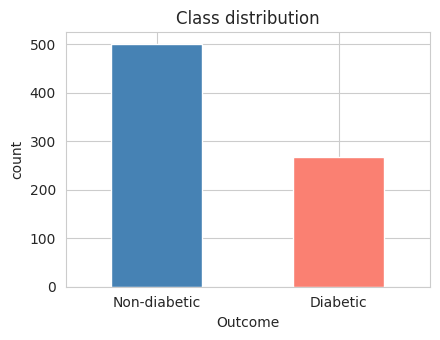

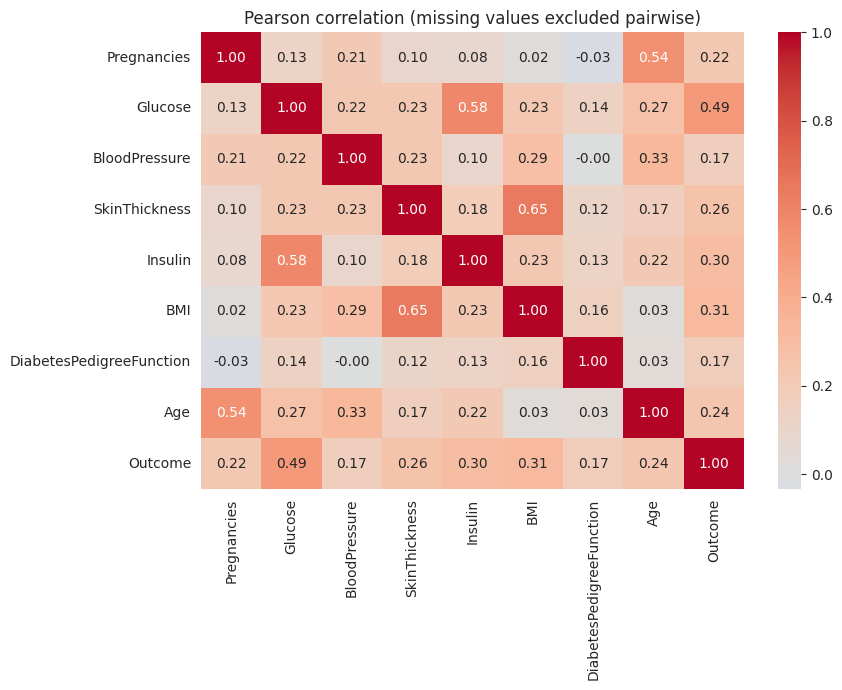

Largest absolute predictor-predictor correlation: 0.648
Correlation with Outcome:
 Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


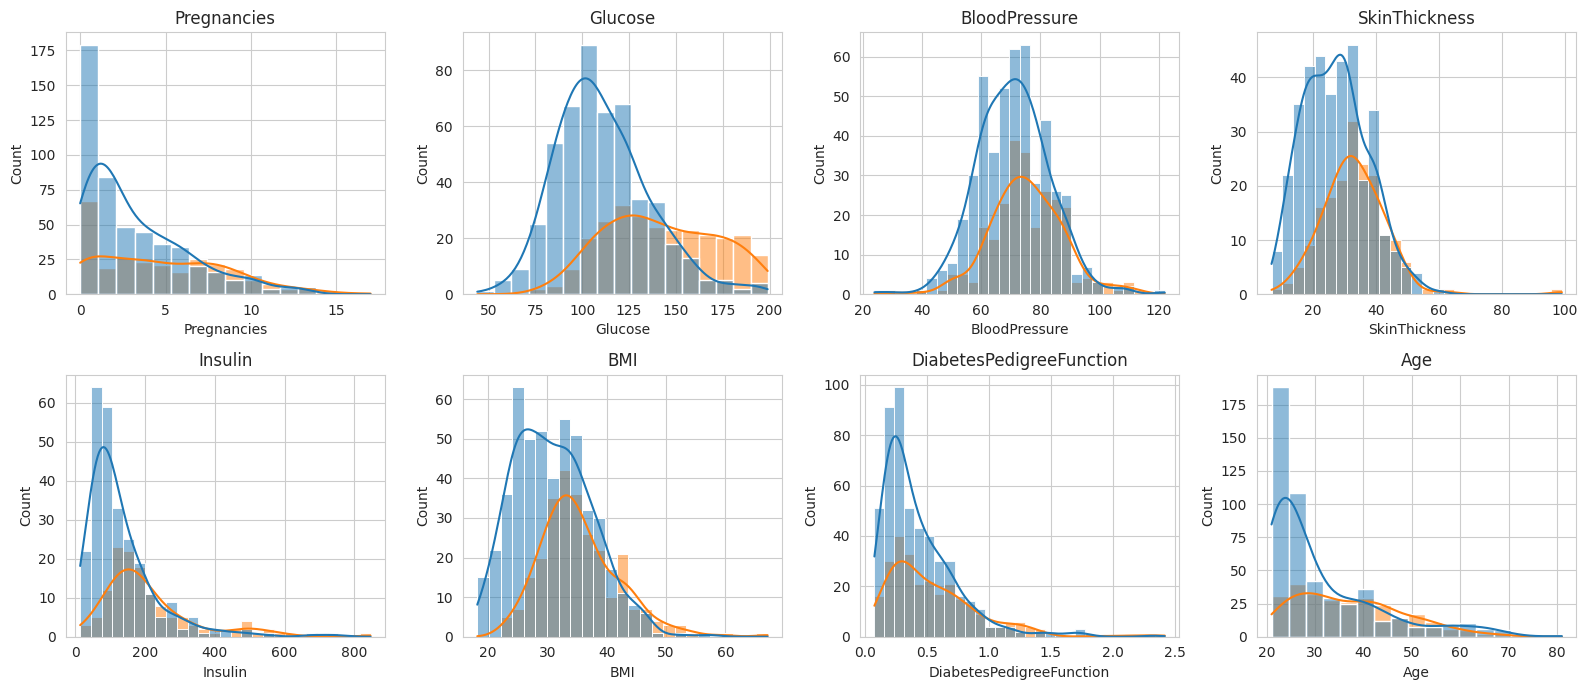

In [ ]:
fig, ax = plt.subplots(figsize=(4.5,3.5))
df["Outcome"].value_counts().sort_index().plot(kind="bar", color=["steelblue","salmon"], ax=ax)
ax.set_xticklabels(["Non-diabetic","Diabetic"], rotation=0); ax.set_ylabel("count")
ax.set_title("Class distribution"); plt.tight_layout(); plt.savefig(f"{OUT}/fig_class_distribution.png", dpi=300); plt.show()

corr = pd.concat([X_all, y_all], axis=1).corr()          # pairwise-complete correlations
plt.figure(figsize=(9,7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson correlation (missing values excluded pairwise)"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_correlation.png", dpi=300); plt.show()
pred_corr = corr.drop(index="Outcome", columns="Outcome").abs().where(~np.eye(len(FEATURES), dtype=bool))
print("Largest absolute predictor-predictor correlation:", round(float(np.nanmax(pred_corr.values)),3))
print("Correlation with Outcome:\n", corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

fig, axes = plt.subplots(2,4, figsize=(16,7))
for ax, f in zip(axes.flatten(), FEATURES):
    sns.histplot(data=pd.concat([X_all, y_all], axis=1), x=f, hue="Outcome", kde=True, ax=ax, legend=False)
    ax.set_title(f)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_feature_distributions.png", dpi=300); plt.show()

## 3. Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.25, random_state=SEED, stratify=y_all)
print(X_train.shape, X_test.shape, "| positives train/test:", y_train.sum(), y_test.sum())

(576, 8) (192, 8) | positives train/test: 201 67


## 4. Models, hyperparameter grids and nested stratified cross-validation



In [ ]:
def imp(): return ("imp", SimpleImputer(strategy="median"))
def scl(): return ("scl", StandardScaler())

def make_models(quick=False):
    g = (lambda full, small: small if quick else full)
    return {
      "Dummy (class prior)": (Pipeline([imp(), ("clf", DummyClassifier(strategy="prior"))]), {}),
      "Logistic Regression": (Pipeline([imp(), scl(), ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
                              {"clf__C": g([0.01,0.1,1,10,100],[0.1,1])}),
      "k-NN": (Pipeline([imp(), scl(), ("clf", KNeighborsClassifier())]),
               {"clf__n_neighbors": g([5,11,21,31],[11,21]), "clf__weights": g(["uniform","distance"],["uniform"])}),
      "SVM (RBF)": (Pipeline([imp(), scl(), ("clf", SVC(kernel="rbf", probability=True, random_state=SEED))]),
                    {"clf__C": g([0.1,1,10],[1,10]), "clf__gamma": g(["scale",0.01,0.1],["scale"])}),
      "Random Forest": (Pipeline([imp(), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
                        {"clf__n_estimators": g([200,500],[100]), "clf__max_depth": g([3,5,None],[3,5]),
                         "clf__min_samples_leaf": g([1,5],[5])}),
      "XGBoost": (Pipeline([imp(), ("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1))]),
                  {"clf__n_estimators": g([100,300],[100]), "clf__max_depth": g([2,3,4],[2,3]),
                   "clf__learning_rate": g([0.03,0.1],[0.1]), "clf__subsample": g([0.8,1.0],[1.0])}),
    }

def metric_dict(y_true, y_pred, y_prob):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "auc": roc_auc_score(y_true, y_prob)}

METRICS = ["accuracy","precision","recall","f1","auc"]
OUTER = RepeatedStratifiedKFold(n_splits=5, n_repeats=1 if QUICK else 2, random_state=SEED)
n_outer = OUTER.get_n_splits()

cv_scores = {}            # model -> DataFrame (one row per outer fold)
for name, (pipe, grid) in make_models(QUICK).items():
    rows = []
    for k, (tr, va) in enumerate(OUTER.split(X_train, y_train)):
        gs = GridSearchCV(pipe, grid, scoring="roc_auc", n_jobs=-1,
                          cv=StratifiedKFold(3, shuffle=True, random_state=SEED + k))
        gs.fit(X_train.iloc[tr], y_train.iloc[tr])
        proba = gs.predict_proba(X_train.iloc[va])[:, 1]
        rows.append(metric_dict(y_train.iloc[va], (proba >= 0.5).astype(int), proba))
    cv_scores[name] = pd.DataFrame(rows)
    print(f"{name:22s} nested-CV AUC = {cv_scores[name]['auc'].mean():.3f}")

Dummy (class prior)    nested-CV AUC = 0.500
Logistic Regression    nested-CV AUC = 0.835
k-NN                   nested-CV AUC = 0.830
SVM (RBF)              nested-CV AUC = 0.832
Random Forest          nested-CV AUC = 0.825
XGBoost                nested-CV AUC = 0.823


### 4.1 Confidence intervals and paired comparisons


In [ ]:
corr_factor = 1.0 / n_outer + 0.25
tcrit = stats.t.ppf(0.975, n_outer - 1)

def cv_ci(x):
    m, s = np.mean(x), np.std(x, ddof=1)
    half = tcrit * np.sqrt(corr_factor) * s
    return m, max(m - half, 0), min(m + half, 1)

cv_rows = []
for name, d in cv_scores.items():
    row = {"Model": name}
    for m in METRICS:
        mu, lo, hi = cv_ci(d[m].values)
        row[m] = f"{mu:.3f} [{lo:.3f}, {hi:.3f}]"
    cv_rows.append(row)
cv_table = pd.DataFrame(cv_rows).set_index("Model")
print(cv_table.to_string())

def corrected_paired_t(a, b):
    d = np.asarray(a) - np.asarray(b)
    if np.allclose(d.std(ddof=1), 0): return 0.0, 1.0
    t = d.mean() / np.sqrt(corr_factor * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), n_outer - 1)

def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(run, 1.0)
    return adj

ref = max(cv_scores, key=lambda n: cv_scores[n]["auc"].mean())
print("\nReference model (highest nested-CV AUC):", ref)
cmp_rows = []
for m in ["auc", "accuracy", "f1"]:
    others = [n for n in cv_scores if n != ref]
    res = [corrected_paired_t(cv_scores[ref][m], cv_scores[n][m]) for n in others]
    adj = holm([r[1] for r in res])
    for n, (dm, p), pa in zip(others, res, adj):
        cmp_rows.append({"metric": m, "reference": ref, "comparator": n,
                         "mean_diff (ref - comp)": round(dm, 4), "p": round(p, 4), "p_Holm": round(pa, 4)})
cmp_table = pd.DataFrame(cmp_rows)
print(cmp_table.to_string(index=False))

                                 accuracy             precision                recall                    f1                   auc
Model                                                                                                                            
Dummy (class prior)  0.651 [0.648, 0.654]  0.000 [0.000, 0.000]  0.000 [0.000, 0.000]  0.000 [0.000, 0.000]  0.500 [0.500, 0.500]
Logistic Regression  0.776 [0.742, 0.810]  0.748 [0.673, 0.823]  0.547 [0.442, 0.653]  0.628 [0.554, 0.702]  0.835 [0.790, 0.881]
k-NN                 0.774 [0.739, 0.809]  0.732 [0.665, 0.799]  0.562 [0.441, 0.683]  0.631 [0.549, 0.714]  0.830 [0.795, 0.865]
SVM (RBF)            0.774 [0.747, 0.802]  0.727 [0.668, 0.786]  0.570 [0.497, 0.642]  0.637 [0.586, 0.688]  0.832 [0.797, 0.868]
Random Forest        0.757 [0.719, 0.795]  0.715 [0.628, 0.803]  0.510 [0.415, 0.605]  0.592 [0.515, 0.670]  0.825 [0.776, 0.873]
XGBoost              0.758 [0.716, 0.799]  0.701 [0.593, 0.810]  0.550 [0.451, 0.649]  0.6

## 5. Final models and held-out test evaluation


In [ ]:
final, best_params, test_prob, test_pred = {}, {}, {}, {}
for name, (pipe, grid) in make_models(QUICK).items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", n_jobs=-1,
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).fit(X_train, y_train)
    final[name] = gs.best_estimator_
    best_params[name] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    test_prob[name] = gs.predict_proba(X_test)[:, 1]
    test_pred[name] = (test_prob[name] >= 0.5).astype(int)
print(json.dumps(best_params, indent=2, default=str))

rng = np.random.default_rng(SEED)
yt = y_test.values; n_te = len(yt)
boot_idx = [rng.integers(0, n_te, n_te) for _ in range(N_BOOT)]
boot_idx = [b for b in boot_idx if 0 < yt[b].sum() < n_te]

def boot_ci(name, metric):
    vals = []
    for b in boot_idx:
        if metric == "auc": vals.append(roc_auc_score(yt[b], test_prob[name][b]))
        else: vals.append(metric_dict(yt[b], test_pred[name][b], test_prob[name][b])[metric])
    return np.percentile(vals, [2.5, 97.5])

test_rows, test_raw = [], {}
for name in final:
    md_ = metric_dict(yt, test_pred[name], test_prob[name]); test_raw[name] = md_
    row = {"Model": name}
    for m in METRICS:
        lo, hi = boot_ci(name, m); row[m] = f"{md_[m]:.3f} [{lo:.3f}, {hi:.3f}]"
    test_rows.append(row)
test_table = pd.DataFrame(test_rows).set_index("Model")
print(test_table.to_string())

# paired bootstrap of the AUC difference against the reference model
auc_cmp = []
for name in final:
    if name == ref: continue
    diffs = [roc_auc_score(yt[b], test_prob[ref][b]) - roc_auc_score(yt[b], test_prob[name][b]) for b in boot_idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    auc_cmp.append({"comparator": name, "AUC diff (ref - comp)": round(np.mean(diffs), 4),
                    "95% CI": f"[{lo:.3f}, {hi:.3f}]", "CI excludes 0": bool(lo > 0 or hi < 0)})
auc_cmp_table = pd.DataFrame(auc_cmp); print("\nTest-set paired bootstrap, reference =", ref); print(auc_cmp_table.to_string(index=False))

{
  "Dummy (class prior)": {},
  "Logistic Regression": {
    "C": 0.1
  },
  "k-NN": {
    "n_neighbors": 21,
    "weights": "distance"
  },
  "SVM (RBF)": {
    "C": 10,
    "gamma": 0.01
  },
  "Random Forest": {
    "max_depth": 5,
    "min_samples_leaf": 5,
    "n_estimators": 500
  },
  "XGBoost": {
    "learning_rate": 0.03,
    "max_depth": 2,
    "n_estimators": 300,
    "subsample": 1.0
  }
}
                                 accuracy             precision                recall                    f1                   auc
Model                                                                                                                            
Dummy (class prior)  0.651 [0.588, 0.719]  0.000 [0.000, 0.000]  0.000 [0.000, 0.000]  0.000 [0.000, 0.000]  0.500 [0.500, 0.500]
Logistic Regression  0.729 [0.661, 0.792]  0.636 [0.509, 0.764]  0.522 [0.406, 0.646]  0.574 [0.466, 0.677]  0.823 [0.762, 0.878]
k-NN                 0.740 [0.677, 0.802]  0.660 [0.529, 0.783]  0.522 [0.

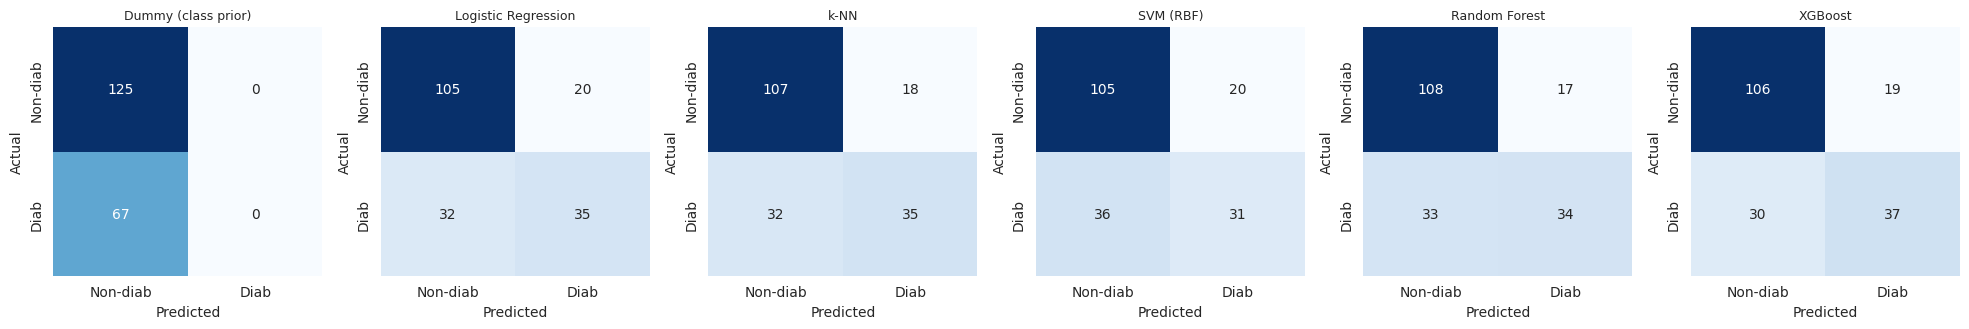

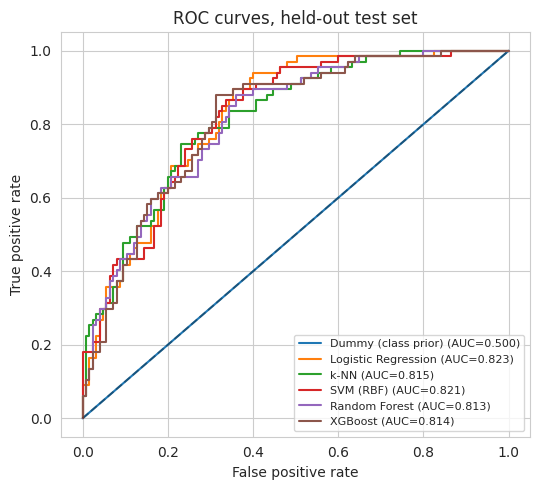

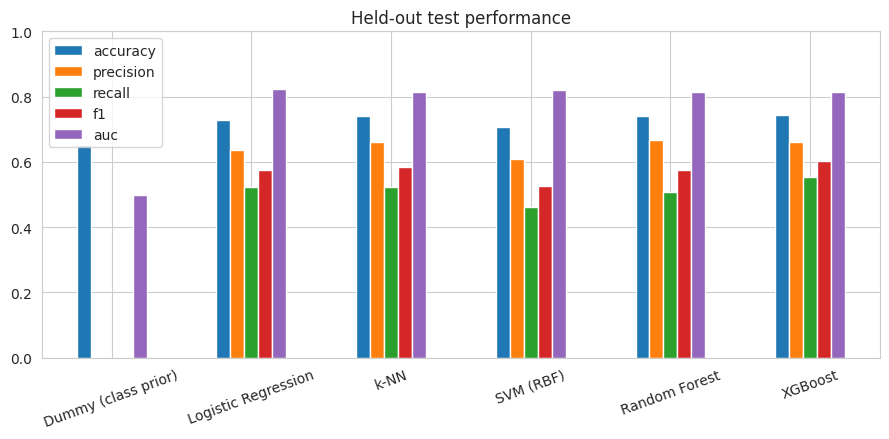

In [ ]:
fig, axes = plt.subplots(1, len(final), figsize=(3.3*len(final), 3.4))
for ax, name in zip(axes, final):
    sns.heatmap(confusion_matrix(yt, test_pred[name]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Non-diab","Diab"], yticklabels=["Non-diab","Diab"])
    ax.set_title(name, fontsize=9); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_confusion_matrices.png", dpi=300); plt.show()

plt.figure(figsize=(5.5,5))
for name in final:
    fpr, tpr, _ = roc_curve(yt, test_prob[name]); plt.plot(fpr, tpr, label=f"{name} (AUC={test_raw[name]['auc']:.3f})")
plt.plot([0,1],[0,1],"k--",alpha=.3); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves, held-out test set"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT}/fig_roc.png", dpi=300); plt.show()

ax = pd.DataFrame(test_raw).T[METRICS].plot(kind="bar", figsize=(9,4.5)); ax.set_ylim(0,1); plt.xticks(rotation=20)
plt.title("Held-out test performance"); plt.tight_layout(); plt.savefig(f"{OUT}/fig_model_comparison.png", dpi=300); plt.show()

## 6. Justification of the explanation model


In [ ]:
EXPLAIN = "XGBoost"
rank = cv_table.index.tolist()
auc_means = {n: cv_scores[n]["auc"].mean() for n in cv_scores}
print("Nested-CV AUC ranking:", sorted(auc_means, key=auc_means.get, reverse=True))
dm, p = corrected_paired_t(cv_scores[ref]["auc"], cv_scores[EXPLAIN]["auc"]) if ref != EXPLAIN else (0.0, 1.0)
print(f"AUC gap to reference ({ref}) = {dm:.4f}, corrected paired-t p = {p:.3f}")
justification = {"reference": ref, "auc_gap_to_reference": float(dm), "p_value": float(p),
                 "xgb_cv_auc": float(auc_means[EXPLAIN])}
if p < 0.05: print("WARNING: XGBoost is significantly worse than the reference; state this in the paper.")
else: print("XGBoost is not statistically distinguishable from the reference on AUC. Say so, and do not claim it is best.")

Nested-CV AUC ranking: ['Logistic Regression', 'SVM (RBF)', 'k-NN', 'Random Forest', 'XGBoost', 'Dummy (class prior)']
AUC gap to reference (Logistic Regression) = 0.0127, corrected paired-t p = 0.301
XGBoost is not statistically distinguishable from the reference on AUC. Say so, and do not claim it is best.


## 7. SHAP configuration and output scale


{
  "explainer": "shap.TreeExplainer",
  "model_output": "raw (log-odds)",
  "feature_perturbation": "tree_path_dependent",
  "background_data": "none",
  "explained_matrix": "imputed, unscaled clinical units",
  "n_explained": 192,
  "base_value_logodds": -0.6270899176597595,
  "max_additivity_error": 2.384185791015625e-06
}

Mean |SHAP| (log-odds):
 Glucose                     0.8811
BMI                         0.6111
Age                         0.2963
DiabetesPedigreeFunction    0.2408
Pregnancies                 0.2144
Insulin                     0.1904
SkinThickness               0.0498
BloodPressure               0.0496
dtype: float32


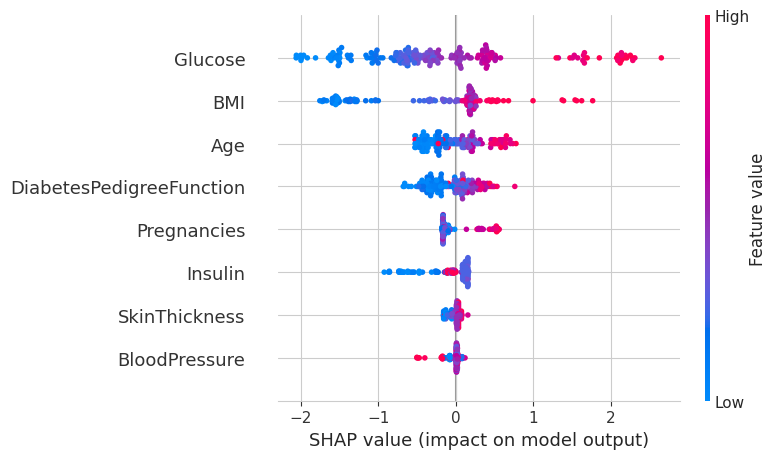

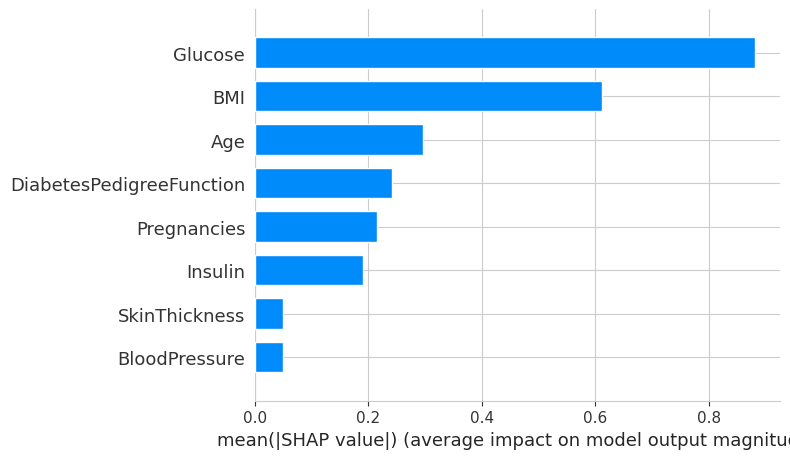

In [ ]:
xgb_pipe = final[EXPLAIN]
imputer, xgb_clf = xgb_pipe.named_steps["imp"], xgb_pipe.named_steps["clf"]
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=FEATURES, index=X_test.index)
X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=FEATURES, index=X_train.index)

explainer = shap.TreeExplainer(xgb_clf, feature_perturbation="tree_path_dependent", model_output="raw")
sv = np.asarray(explainer.shap_values(X_test_imp))
base = float(np.ravel(explainer.expected_value)[0])
margin = xgb_clf.predict(X_test_imp, output_margin=True)
add_err = float(np.max(np.abs(base + sv.sum(axis=1) - margin)))
shap_config = {"explainer": "shap.TreeExplainer", "model_output": "raw (log-odds)",
               "feature_perturbation": "tree_path_dependent", "background_data": "none",
               "explained_matrix": "imputed, unscaled clinical units", "n_explained": int(len(sv)),
               "base_value_logodds": base, "max_additivity_error": add_err}
print(json.dumps(shap_config, indent=2))
assert add_err < 1e-3, "SHAP additivity check failed"

imp_global = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print("\nMean |SHAP| (log-odds):\n", imp_global.round(4))
plt.figure(); shap.summary_plot(sv, X_test_imp, show=False); plt.tight_layout()
plt.savefig(f"{OUT}/fig_shap_beeswarm.png", dpi=300, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(sv, X_test_imp, plot_type="bar", show=False); plt.tight_layout()
plt.savefig(f"{OUT}/fig_shap_bar.png", dpi=300, bbox_inches="tight"); plt.show()

## 8. Explanation texts (templates, non-causal wording)


In [ ]:
K = 3
units = {"Pregnancies":"", "Glucose":" mg/dL", "BloodPressure":" mm Hg", "SkinThickness":" mm",
         "Insulin":" mu U/ml", "BMI":" kg/m2", "DiabetesPedigreeFunction":"", "Age":" years"}

plain = {
 "Glucose": {"up":"your blood sugar reading is in a range the model links with higher estimated risk",
             "down":"your blood sugar reading is in a range the model links with lower estimated risk"},
 "BMI": {"up":"your body mass index (weight relative to height) is in a range the model links with higher estimated risk",
         "down":"your body mass index is in a range the model links with lower estimated risk"},
 "Age": {"up":"your age falls in a group the model links with higher estimated risk",
         "down":"your age falls in a group the model links with lower estimated risk"},
 "DiabetesPedigreeFunction": {"up":"your family history score is in a range the model links with higher estimated risk",
                              "down":"your family history score is in a range the model links with lower estimated risk"},
 "Pregnancies": {"up":"your number of pregnancies is in a range the model links with higher estimated risk",
                 "down":"your number of pregnancies is in a range the model links with lower estimated risk"},
 "BloodPressure": {"up":"your blood pressure reading is in a range the model links with higher estimated risk",
                   "down":"your blood pressure reading is in a range the model links with lower estimated risk"},
 "SkinThickness": {"up":"your skinfold measurement is in a range the model links with higher estimated risk",
                   "down":"your skinfold measurement is in a range the model links with lower estimated risk"},
 "Insulin": {"up":"your insulin level is in a range the model links with higher estimated risk",
             "down":"your insulin level is in a range the model links with lower estimated risk"},
}
assert len({p for d in plain.values() for p in d.values()}) == 16   # phrases must be unique

def build_pair(feat, value, v):
    d = "up" if v >= 0 else "down"
    clinical = f"{feat} = {value:.2f}{units[feat]}; SHAP = {v:+.3f} (log-odds)."
    patient  = f"The model's estimate reflects that {plain[feat][d]}."
    return clinical, patient, d

def explain_row(i, k=K):
    sv_i = sv[i]; top = np.argsort(-np.abs(sv_i))[:k]
    c, p, dirs = [], [], []
    for j in top:
        f = FEATURES[j]; cl, pa, d = build_pair(f, X_test_imp.iloc[i][f], sv_i[j])
        c.append(cl); p.append(pa); dirs.append((f, d))
    return {"patient_id": i, "clinical_text": " ".join(c), "patient_text": " ".join(p), "truth_dirs": dirs}

expl = pd.DataFrame([explain_row(i) for i in range(len(X_test_imp))])   # ALL test records
print(len(expl), "explanation pairs")
print("CLINICAL:\n", expl.loc[0, "clinical_text"]); print("\nPATIENT:\n", expl.loc[0, "patient_text"])

192 explanation pairs
CLINICAL:
 Glucose = 104.00 mg/dL; SHAP = -0.576 (log-odds). Pregnancies = 13.00; SHAP = +0.547 (log-odds). Age = 38.00 years; SHAP = +0.218 (log-odds).

PATIENT:
 The model's estimate reflects that your blood sugar reading is in a range the model links with lower estimated risk. The model's estimate reflects that your number of pregnancies is in a range the model links with higher estimated risk. The model's estimate reflects that your age falls in a group the model links with higher estimated risk.


## 9. Explanation fidelity and feature-direction preservation


In [ ]:
# (a) coverage
tot = np.abs(sv).sum(axis=1)
cov = {k: np.abs(np.sort(np.abs(sv), axis=1)[:, ::-1][:, :k]).sum(axis=1) / tot for k in (1, 2, 3, 4, 5)}
coverage = {f"top{k}_mean": float(v.mean()) for k, v in cov.items()}
coverage["top3_share_ge_0.80"] = float((cov[3] >= 0.80).mean())
print("Top-k coverage of sum|SHAP|:", {k: round(v, 3) for k, v in coverage.items()})

# (b) deletion test
med = X_train_imp.median()
rng2 = np.random.default_rng(SEED)
d_top, d_rand, pred_shift = [], [], []
for i in range(len(X_test_imp)):
    x = X_test_imp.iloc[[i]].copy(); m0 = margin[i]
    top = np.argsort(-np.abs(sv[i]))[:K]
    xt = x.copy(); xt.iloc[0, top] = med.values[top]
    d_top.append(xgb_clf.predict(xt, output_margin=True)[0] - m0)
    rr = []
    for _ in range(20):
        r = rng2.choice(len(FEATURES), K, replace=False); xr = x.copy(); xr.iloc[0, r] = med.values[r]
        rr.append(xgb_clf.predict(xr, output_margin=True)[0] - m0)
    d_rand.append(np.mean(np.abs(rr)))
d_top = np.array(d_top)
rho, p_rho = stats.spearmanr(-sv[np.arange(len(sv))[:, None], np.argsort(-np.abs(sv), axis=1)[:, :K]].sum(axis=1), d_top)
w = stats.wilcoxon(np.abs(d_top), d_rand)
deletion = {"mean_abs_change_top_k": float(np.abs(d_top).mean()), "mean_abs_change_random_k": float(np.mean(d_rand)),
            "wilcoxon_p": float(w.pvalue), "spearman_rho_sumSHAP_vs_change": float(rho)}
print("Deletion test:", {k: round(v, 4) for k, v in deletion.items()})

# (c) direction recovery from the generated TEXT (independent of the template used to write it)
phrase2dir = {(f, ph): d for f, dd in plain.items() for d, ph in dd.items()}
def parse_patient(text):
    return {f: d for (f, ph), d in phrase2dir.items() if ph in text}
def parse_clinical(text):
    return {m.group(1): ("up" if m.group(2) == "+" else "down") for m in re.finditer(r"(\w+) = [^;]+; SHAP = ([+-])", text)}
ok_p = ok_c = n_items = 0
for _, r in expl.iterrows():
    pp, cc = parse_patient(r.patient_text), parse_clinical(r.clinical_text)
    for f, d in r.truth_dirs:
        n_items += 1; ok_p += pp.get(f) == d; ok_c += cc.get(f) == d
direction = {"items_checked": n_items, "patient_text_agreement": ok_p / n_items, "clinical_text_agreement": ok_c / n_items}
print("Direction preservation:", direction)

Top-k coverage of sum|SHAP|: {'top1_mean': 0.429, 'top2_mean': 0.642, 'top3_mean': 0.775, 'top4_mean': 0.866, 'top5_mean': 0.928, 'top3_share_ge_0.80': 0.469}
Deletion test: {'mean_abs_change_top_k': 1.5968, 'mean_abs_change_random_k': 0.7457, 'wilcoxon_p': 0.0, 'spearman_rho_sumSHAP_vs_change': 0.99}
Direction preservation: {'items_checked': 576, 'patient_text_agreement': 1.0, 'clinical_text_agreement': 1.0}


## 10. Readability on all test records

Distinct patient texts: 116 of 192
           sample clinical_mean clinical_sd patient_mean patient_sd  mean_diff         diff_95CI wilcoxon_p  cohen_dz
fkgl  all (n=192)      4.268282    2.201369    10.646643   0.428248    6.37836      [6.11, 6.64]        0.0  3.305026
fre   all (n=192)     74.854065    16.04972    54.304171   2.161261 -20.549894  [-22.56, -18.54]        0.0 -1.439709
smog  all (n=192)      5.841843    1.603028    12.208317    0.63647   6.366474      [6.21, 6.53]        0.0  5.387325
fkgl     first 40      4.494903    2.318913    10.672532   0.459582   6.177629      [5.56, 6.81]        0.0  3.098709
fre      first 40     73.196533   16.907788    54.078976   2.314421 -19.117557  [-23.67, -14.69]        0.0 -1.283722
smog     first 40      6.040941    1.568822    12.287043   0.672067   6.246102      [5.91, 6.59]        0.0  5.651518


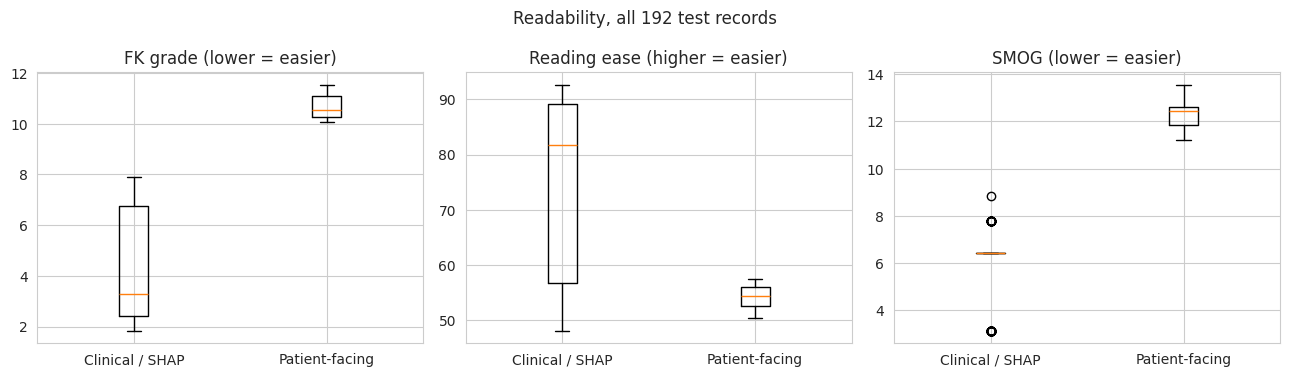

In [ ]:
def score(texts):
    return pd.DataFrame({"fkgl": [textstat.flesch_kincaid_grade(t) for t in texts],
                         "fre":  [textstat.flesch_reading_ease(t)   for t in texts],
                         "smog": [textstat.smog_index(t)            for t in texts]})
sc_c, sc_p = score(expl.clinical_text), score(expl.patient_text)
print("Distinct patient texts:", expl.patient_text.nunique(), "of", len(expl))

def summarize(c, p, label):
    rows = {}
    for m in ["fkgl", "fre", "smog"]:
        diff = (p[m] - c[m]).values
        bs = [rng.choice(diff, len(diff)).mean() for _ in range(N_BOOT)]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        wp = stats.wilcoxon(p[m], c[m]).pvalue if np.any(diff != 0) else 1.0
        rows[m] = {"clinical_mean": c[m].mean(), "clinical_sd": c[m].std(ddof=1),
                   "patient_mean": p[m].mean(), "patient_sd": p[m].std(ddof=1),
                   "mean_diff": diff.mean(), "diff_95CI": f"[{lo:.2f}, {hi:.2f}]",
                   "wilcoxon_p": wp, "cohen_dz": diff.mean() / (diff.std(ddof=1) or np.nan)}
    t = pd.DataFrame(rows).T; t.insert(0, "sample", label); return t
read_all   = summarize(sc_c, sc_p, f"all (n={len(expl)})")
read_first = summarize(sc_c.iloc[:40], sc_p.iloc[:40], "first 40")
readability_table = pd.concat([read_all, read_first]); print(readability_table.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (m, t) in zip(axes, [("fkgl","FK grade (lower = easier)"),("fre","Reading ease (higher = easier)"),("smog","SMOG (lower = easier)")]):
    ax.boxplot([sc_c[m], sc_p[m]], labels=["Clinical / SHAP","Patient-facing"]); ax.set_title(t)
plt.suptitle(f"Readability, all {len(expl)} test records"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_readability.png", dpi=300); plt.show()

## 11. Export everything for the paper


In [ ]:
cv_table.to_csv(f"{OUT}/table_nested_cv.csv"); cmp_table.to_csv(f"{OUT}/table_cv_paired_tests.csv", index=False)
test_table.to_csv(f"{OUT}/table_test_performance.csv"); auc_cmp_table.to_csv(f"{OUT}/table_test_auc_comparison.csv", index=False)
readability_table.to_csv(f"{OUT}/table_readability.csv"); expl.drop(columns="truth_dirs").to_csv(f"{OUT}/explanations_all_test.csv", index=False)
results = {"versions": versions, "split": {"train": int(len(X_train)), "test": int(len(X_test)), "test_size": 0.25},
           "missing_zeros": missing_report, "best_params": best_params, "reference_model": ref,
           "nested_cv_outer_folds": int(n_outer), "justification": justification,
           "nested_cv": cv_table.to_dict(), "cv_paired_tests": cmp_table.to_dict("records"),
           "test_performance": test_table.to_dict(), "test_auc_paired_bootstrap": auc_cmp_table.to_dict("records"),
           "shap_config": shap_config, "global_importance": imp_global.round(4).to_dict(),
           "max_pred_corr": float(np.nanmax(pred_corr.values)), "coverage": coverage, "deletion": deletion, "direction": direction,
           "readability": readability_table.round(4).reset_index().to_dict("records")}
json.dump(results, open(f"{OUT}/results.json", "w"), indent=2, default=str)
print("Saved to", OUT, "->", sorted(os.listdir(OUT)))
try:                                   # Colab only: bundle and download everything the paper needs
    import shutil; from google.colab import files
    shutil.make_archive("paper_outputs", "zip", OUT); files.download("paper_outputs.zip")
except ImportError:
    pass

Saved to outputs -> ['explanations_all_test.csv', 'fig_class_distribution.png', 'fig_confusion_matrices.png', 'fig_correlation.png', 'fig_feature_distributions.png', 'fig_model_comparison.png', 'fig_readability.png', 'fig_roc.png', 'fig_shap_bar.png', 'fig_shap_beeswarm.png', 'results.json', 'table_cv_paired_tests.csv', 'table_nested_cv.csv', 'table_readability.csv', 'table_test_auc_comparison.csv', 'table_test_performance.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>